# Tratamento da base MOSC: ausentes, duplicidades, outliers e carga no MySQL

**Entrada:** `20260806_MOSC_baseDivulgacao.csv` (1.113.949 OSCs, 44 colunas) · **Saída:** base tratada em CSV, tabelas normalizadas, `schema.sql` e script de importação para o MySQL.

O tratamento segue seis etapas:

1. **Dados ausentes:** diagnosticar o tipo de cada ausência e tratar só o que tem evidência.
2. **Duplicidades:** chave, CNPJ válido, entidades repetidas.
3. **Outliers:** contagens, datas e coordenadas.
4. **Validação:** antes x depois e verificações de integridade.
5. **Nova base:** esquema, dicionário de dados e exportação.
6. **MySQL:** DDL, importação e teste de integridade.

**Princípios.**

- Ausência não é sempre erro. Muitos campos estão vazios por definição (por exemplo, só quem saiu do cadastro tem data de fechamento).
- Só se imputa com evidência, como o código IBGE ou o endereço, e nunca com média ou moda "no escuro".
- Nada é descartado em silêncio. Cada correção gera uma coluna de sinalização (`flag_*`) e uma linha em `log_tratamento`; os valores originais alterados ficam em tabela de auditoria.
- Outlier estatístico não é erro. Só se corrige o que é impossível ou incoerente.

**Requisitos.** Python 3.9+, `pandas`, `numpy`, `matplotlib` e `seaborn`; cerca de 3 GB de RAM. Para a carga no MySQL, `pymysql` (`pip install pymysql`).

---
## Etapa 0 · Preparação e leitura

In [1]:
import os, re, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
})
COR, VERM, CINZA = "#1f4e79", "#d1495b", "#8d99ae"
PAL_SIT = {"Ativa": "#2a9d8f", "Inapta": "#e9c46a", "Suspensa": "#f4a261", "Nula ou Baixada": "#d1495b"}

def br(x, d=0):
    """Formata número no padrão brasileiro: 1.234.567,89"""
    s = f"{x:,.{d}f}"
    return s.replace(",", "X").replace(".", ",").replace("X", ".")

fmt_eixo = mtick.FuncFormatter(lambda x, _: br(x))
pd.options.display.float_format = lambda v: br(v, 2)

import csv, gc, json
SAIDA = "saida_tratamento"                      # pasta com todos os arquivos gerados
os.makedirs(SAIDA, exist_ok=True)

LOG = []                                        # trilha de auditoria: cada regra aplicada e quantos registros afetou
def log(etapa, regra, coluna, qtd, acao):
    LOG.append({"etapa": etapa, "regra": regra, "coluna": coluna, "registros_afetados": int(qtd), "acao": acao})


In [2]:
CAMINHO = "/mnt/user-data/uploads/20260806_MOSC_baseDivulgacao.csv"   # ajuste para o seu caminho
LIMPO   = "mosc_utf8.csv"                                               # cópia com encoding corrigido
DATA_REF = pd.Timestamp("2026-08-06")                                   # data de divulgação (vem no nome do arquivo)

# O arquivo mistura UTF-8 e Latin-1 até dentro da mesma linha (ex.: "não" em UTF-8 e "Ç" em Latin-1).
# Estratégia: ler tudo como Latin-1 (nunca falha) e "consertar" só as sequências que são UTF-8 válido.
PADRAO = re.compile("[\u00c2-\u00df][\u0080-\u00bf]|[\u00e0-\u00ef][\u0080-\u00bf]{2}|[\u00f0-\u00f4][\u0080-\u00bf]{3}")
def _conserta(m):
    try:    return m.group(0).encode("latin-1").decode("utf-8")
    except UnicodeDecodeError: return m.group(0)

if not os.path.exists(LIMPO):
    with open(CAMINHO, encoding="latin-1", newline="") as fin, open(LIMPO, "w", encoding="utf-8", newline="") as fout:
        for linha in fin:
            fout.write(PADRAO.sub(_conserta, linha))

# tudo como texto na leitura: evita que CNPJ/CNAE percam zeros à esquerda
df = pd.read_csv(LIMPO, sep=";", encoding="utf-8", dtype=str)

print(f"{br(df.shape[0])} linhas x {df.shape[1]} colunas")
print(f"Memória: {br(df.memory_usage(deep=True).sum() / 1e6)} MB")
print(f"CNPJs duplicados: {df['cnpj'].duplicated().sum()}  -> cada linha é uma OSC única")

# auditoria do encoding: sobrou algum caractere "quebrado"?
txt_cols = ["tx_razao_social_osc", "tx_nome_fantasia_osc", "tx_endereco_completo", "municipio_nome", "matriz_filial", "removida_do_mosc"]
quebrados = sum(df[c].str.contains("[ÃÂ][\u0080-\u00bf]|\ufffd", na=False, regex=True).sum() for c in txt_cols)
print(f"Células com caracteres suspeitos após a correção: {quebrados}")
print("Exemplos:", df["municipio_nome"].dropna().sample(3, random_state=7).tolist(), "|", df["matriz_filial"].unique().tolist(), "|", df["removida_do_mosc"].unique().tolist())


1.113.949 linhas x 44 colunas
Memória: 2.659 MB
CNPJs duplicados: 0  -> cada linha é uma OSC única
Células com caracteres suspeitos após a correção: 33
Exemplos: ['PARAÍSO DO TOCANTINS', 'SÃO JOSÉ DO OURO', 'TIMÓTEO'] | ['Não Identificado', 'Matriz', 'Filial'] | ['sim', 'não']


**Leitura.** O CSV mistura UTF-8 e Latin-1, até dentro da mesma linha. Corrigir o encoding é o primeiro tratamento: sem isso, "não" e "Ç" não podem ser lidos juntos e os acentos se corrompem em qualquer destino, inclusive o MySQL. Sobram 33 células suspeitas, o que é desprezível.

---
## Etapa 1 · Dados ausentes e padronização

Primeiro o diagnóstico: quanto falta, onde e **por quê**. A tabela abaixo separa três tipos de ausência, e cada uma recebe um tratamento diferente.

In [3]:
col_area  = [c for c in df.columns if c.startswith("Area_")]
col_sub   = [c for c in df.columns if c.startswith("SubArea_")]
col_flags = col_area + col_sub

# "foto" dos ausentes ANTES do tratamento (usada no comparativo final)
ANTES = df.drop(columns=col_flags).isna().sum()
ANTES["flags de área/subárea (26 colunas, em bloco)"] = df[col_flags].isna().all(axis=1).sum()
ANTES = ANTES[ANTES > 0].sort_values(ascending=False)

tab = ANTES.to_frame("ausentes")
tab["%"] = tab["ausentes"] / len(df) * 100
print(tab.to_string(formatters={"ausentes": br, "%": lambda v: br(v, 2)}))

# "vazios disfarçados": texto que só tem espaços (isna() não enxerga)
print("\nTexto em branco (só espaços), invisível ao isna():")
for c in ["tx_razao_social_osc", "tx_nome_fantasia_osc", "tx_endereco_completo"]:
    print(f"  {c:<24}{int((df[c].str.strip() == '').sum())}")

cd_ok = df["cd_municipio"].str.fullmatch(r"\d{7}").fillna(False)
print(f"\ncd_municipio inválido ('0' ou ausente): {br((~cd_ok).sum())}")
print(f"  ...dos quais também sem coordenadas   : {br((~cd_ok & df['latitude'].isna()).sum())}")
print(f"UF ausente: {br(df['UF_Sigla'].isna().sum())} | recuperável pelo código do município: {br((df['UF_Sigla'].isna() & cd_ok).sum())}")

plano = pd.DataFrame([
    ("tx_nome_fantasia_osc",            "opcional (não é erro)",                     "manter NULL; textos em branco viram NULL"),
    ("data_fechamento, ano_fechamento", "estrutural (só existe p/ quem saiu)",       "manter NULL"),
    ("cnae_secundaria",                 "estrutural (sem atividade secundária)",     "manter NULL; normalizar em tabela 1:N"),
    ("flags de área/subárea",           "bloco inteiro sem classificação",           "preencher 0 + coluna sem_classificacao_area"),
    ("UF_Sigla, municipio_nome",        "recuperável (código IBGE do município)",    "imputar UF pelos 2 primeiros dígitos e nome por lookup"),
    ("cd_municipio ('0' / ausente)",    "irrecuperável",                             "NULL"),
    ("latitude, longitude",             "irrecuperável sem município",               "manter NULL + flag_coord_ausente"),
    ("cnae (ausente ou 4 dígitos)",     "inválido / ausente",                        "NULL + flag_cnae_invalido"),
    ("natureza_juridica, dt_fundacao",  "693 linhas, todas baixadas",                "rótulo 'Não informada'; data NULL"),
    ("matriz_filial = Não Identificado","derivável do CNPJ (ordem 0001 = matriz)",   "derivar do CNPJ + flag"),
    ("tx_endereco_completo",            "irrecuperável",                             "manter NULL"),
], columns=["coluna", "tipo de ausência", "tratamento"])
print("\nPlano de tratamento dos ausentes")
print(plano.to_string(index=False))


                                              ausentes     %
ano_fechamento                               1.054.202 94,64
data_fechamento                              1.054.202 94,64
cnae_secundaria                                657.397 59,01
tx_nome_fantasia_osc                           488.830 43,88
flags de área/subárea (26 colunas, em bloco)    26.134  2,35
cnae                                            12.927  1,16
tx_endereco_completo                            12.308  1,10
municipio_nome                                   1.012  0,09
UF_Sigla                                         1.012  0,09
natureza_juridica                                  693  0,06
dt_fundacao_osc                                    693  0,06
longitude                                          184  0,02
latitude                                           184  0,02
cd_municipio                                       152  0,01

Texto em branco (só espaços), invisível ao isna():
  tx_razao_social_osc     0
  tx_

**Leitura.**

- **Estruturais ou opcionais** (não são erros): data/ano de fechamento (94,6%), CNAE secundária (59,0%) e nome fantasia (43,9%).
- **Recuperáveis com evidência:** 828 das 1.012 UF ausentes têm código IBGE de município válido, e a UF vem dos dois primeiros dígitos.
- **Irrecuperáveis:** 184 OSCs sem município e sem coordenadas (as mesmas linhas); endereço ausente (12.308); CNAE ausente (12.927).
- **"Vazios disfarçados":** 28 nomes fantasia só com espaços, invisíveis ao `isna()`.

A célula a seguir constrói a base tratada `t` aplicando as regras do plano: padroniza texto, recupera UF e município, rotula natureza jurídica, deriva matriz/filial, valida CNAE, normaliza o CNAE secundário e preenche as flags de área com indicador. Cada regra grava no log.

In [4]:
# ---------------------------------------------------------------- tabelas de apoio ----------------
IBGE_UF = {"11":"RO","12":"AC","13":"AM","14":"RR","15":"PA","16":"AP","17":"TO","21":"MA","22":"PI","23":"CE","24":"RN",
           "25":"PB","26":"PE","27":"AL","28":"SE","29":"BA","31":"MG","32":"ES","33":"RJ","35":"SP","41":"PR","42":"SC",
           "43":"RS","50":"MS","51":"MT","52":"GO","53":"DF"}
COD_UF  = {v: k for k, v in IBGE_UF.items()}
NOME_UF = {"RO":"Rondônia","AC":"Acre","AM":"Amazonas","RR":"Roraima","PA":"Pará","AP":"Amapá","TO":"Tocantins","MA":"Maranhão",
           "PI":"Piauí","CE":"Ceará","RN":"Rio Grande do Norte","PB":"Paraíba","PE":"Pernambuco","AL":"Alagoas","SE":"Sergipe",
           "BA":"Bahia","MG":"Minas Gerais","ES":"Espírito Santo","RJ":"Rio de Janeiro","SP":"São Paulo","PR":"Paraná",
           "SC":"Santa Catarina","RS":"Rio Grande do Sul","MS":"Mato Grosso do Sul","MT":"Mato Grosso","GO":"Goiás","DF":"Distrito Federal"}
REGIAO  = {**dict.fromkeys(["AC","AP","AM","PA","RO","RR","TO"], "Norte"),
           **dict.fromkeys(["AL","BA","CE","MA","PB","PE","PI","RN","SE"], "Nordeste"),
           **dict.fromkeys(["DF","GO","MT","MS"], "Centro-Oeste"),
           **dict.fromkeys(["ES","MG","RJ","SP"], "Sudeste"),
           **dict.fromkeys(["PR","RS","SC"], "Sul")}
NAT_JUR = {"3069": "Fundação privada", "3220": "Organização religiosa", "3301": "Organização social (OS)", "3999": "Associação privada"}

# nomes curtos para as 26 flags (o MySQL limita identificadores a 64 caracteres; um dos originais tem 65)
FLAGS = [
 ("Area_Assistencia_social", "area_assistencia_social", "Atua em Assistência social"),
 ("Area_Associacoes_patronais_e_profissionais", "area_assoc_patronais_profissionais", "Atua em Associações patronais e profissionais"),
 ("Area_Cultura_e_recreacao", "area_cultura_recreacao", "Atua em Cultura e recreação"),
 ("Area_Desenvolvimento_e_defesa_de_direitos_e_interesses", "area_desenv_defesa_direitos", "Atua em Desenvolvimento e defesa de direitos e interesses"),
 ("Area_Educacao_e_pesquisa", "area_educacao_pesquisa", "Atua em Educação e pesquisa"),
 ("Area_Outras_atividades_associativas", "area_outras_ativ_associativas", "Atua em Outras atividades associativas"),
 ("Area_Religiao", "area_religiao", "Atua em Religião"),
 ("Area_Saude", "area_saude", "Atua em Saúde"),
 ("SubArea_Assistencia_social", "sub_assistencia_social", "Subárea Assistência social"),
 ("SubArea_Associacoes_de_atividades_nao_especificadas_anteriormente", "sub_assoc_nao_especificadas", "Subárea Associações de atividades não especificadas anteriormente"),
 ("SubArea_Associacoes_de_produtores_rurais_pescadores_e_similares", "sub_produtores_rurais_pescadores", "Subárea Associações de produtores rurais, pescadores e similares"),
 ("SubArea_Associacoes_empresariais_e_patronais", "sub_empresariais_patronais", "Subárea Associações empresariais e patronais"),
 ("SubArea_Associacoes_profissionais", "sub_profissionais", "Subárea Associações profissionais"),
 ("SubArea_Atividades_de_apoio_a_educacao", "sub_apoio_educacao", "Subárea Atividades de apoio à educação"),
 ("SubArea_Cultura_e_arte", "sub_cultura_arte", "Subárea Cultura e arte"),
 ("SubArea_Desenvolvimento_e_defesa_de_direitos", "sub_desenv_defesa_direitos", "Subárea Desenvolvimento e defesa de direitos"),
 ("SubArea_Educacao_infantil", "sub_educacao_infantil", "Subárea Educação infantil"),
 ("SubArea_Educacao_profissional", "sub_educacao_profissional", "Subárea Educação profissional"),
 ("SubArea_Ensino_fundamental", "sub_ensino_fundamental", "Subárea Ensino fundamental"),
 ("SubArea_Ensino_superior", "sub_ensino_superior", "Subárea Ensino superior"),
 ("SubArea_Esportes_e_recreacao", "sub_esportes_recreacao", "Subárea Esportes e recreação"),
 ("SubArea_Estudos_e_pesquisas", "sub_estudos_pesquisas", "Subárea Estudos e pesquisas"),
 ("SubArea_Hospitais", "sub_hospitais", "Subárea Hospitais"),
 ("SubArea_Outras_formas_de_educacao_ensino", "sub_outras_formas_educacao", "Subárea Outras formas de educação e ensino"),
 ("SubArea_Outros_servicos_de_saude", "sub_outros_servicos_saude", "Subárea Outros serviços de saúde"),
 ("SubArea_Religiao", "sub_religiao", "Subárea Religião"),
]
assert [f[0] for f in FLAGS] == col_flags
print("Maior nome de coluna original:", max(map(len, df.columns)), "caracteres (limite do MySQL: 64)")

# ---------------------------------------------------------------- 1) texto -------------------------------
def limpa(s):
    """tira espaços das pontas, colapsa espaços múltiplos, transforma vazio em NULL e padroniza em MAIÚSCULAS"""
    s = s.str.replace(r"\s+", " ", regex=True).str.strip()
    return s.mask(s == "").str.upper()

t = pd.DataFrame({"cnpj": df["cnpj"]})
t["cnpj_basico"] = t["cnpj"].str[:8]
t["cnpj_ordem"]  = t["cnpj"].str[8:12]

for orig, novo in [("tx_razao_social_osc", "razao_social"), ("tx_nome_fantasia_osc", "nome_fantasia"), ("tx_endereco_completo", "endereco_completo")]:
    t[novo] = limpa(df[orig])
    alterados = int((df[orig].fillna("") != t[novo].fillna("")).sum())
    log("texto", "trim + espaços múltiplos + vazio->NULL + MAIÚSCULAS", orig, alterados, "padronizado")
    print(f"{orig:<24} {br(alterados):>10} valores padronizados")
em_branco = int(((df["tx_nome_fantasia_osc"].str.strip() == "")).sum())
log("ausentes", "nome fantasia só com espaços", "tx_nome_fantasia_osc", em_branco, "convertido em NULL")

# ---------------------------------------------------------------- 2) localização -------------------------
t["cd_municipio"] = df["cd_municipio"].where(df["cd_municipio"].str.fullmatch(r"\d{7}").fillna(False))
log("ausentes", "código IBGE inválido ('0')", "cd_municipio", (df["cd_municipio"].notna() & t["cd_municipio"].isna()).sum(), "convertido em NULL")

uf_ibge = t["cd_municipio"].str[:2].map(IBGE_UF)
conflito = (df["UF_Sigla"].notna() & uf_ibge.notna() & (df["UF_Sigla"] != uf_ibge)).sum()
print(f"\nUF declarada x UF do código IBGE, conflitos: {conflito}")
t["uf"] = df["UF_Sigla"].fillna(uf_ibge)
t["flag_uf_imputada"] = (df["UF_Sigla"].isna() & t["uf"].notna()).astype("int8")
log("ausentes", "UF ausente recuperada pelo código IBGE", "UF_Sigla", t["flag_uf_imputada"].sum(), "imputada")

nomes = df.dropna(subset=["municipio_nome", "cd_municipio"]).drop_duplicates("cd_municipio").set_index("cd_municipio")["municipio_nome"]
t["municipio_nome"] = df["municipio_nome"].fillna(t["cd_municipio"].map(nomes))
rec = int((df["municipio_nome"].isna() & t["municipio_nome"].notna()).sum())
if rec: log("ausentes", "nome do município recuperado por lookup no código", "municipio_nome", rec, "imputado")

# 2ª tentativa: o nome do município também aparece no próprio endereço ("..., BAIRRO, PESCARIA BRAVA, SC, 88798000")
ext = t["endereco_completo"].str.extract(r"(?:^|,\s*)([^,]+),\s*([A-Z]{2})(?:,\s*\d{5,8})?$")
ext.columns = ["nome_end", "uf_end"]
comparavel = t["municipio_nome"].notna() & ext["nome_end"].notna() & (ext["uf_end"] == t["uf"])
concorda = (ext.loc[comparavel, "nome_end"] == t.loc[comparavel, "municipio_nome"]).mean() * 100
print(f"Validação da extração: o nome no endereço coincide com o município cadastrado em {br(concorda, 1)}% de {br(comparavel.sum())} linhas comparáveis")
cand = ext[t["municipio_nome"].isna() & t["cd_municipio"].notna() & (ext["uf_end"] == t["uf"]) & ext["nome_end"].notna()]
moda = cand.assign(cd=t["cd_municipio"]).groupby("cd")["nome_end"].agg(lambda s: s.mode().iat[0])
falta = t["municipio_nome"].isna() & t["cd_municipio"].notna()
t.loc[falta, "municipio_nome"] = t.loc[falta, "cd_municipio"].map(moda)
rec2 = int((falta & t["municipio_nome"].notna()).sum())
log("ausentes", "nome do município recuperado do endereço (moda por código IBGE)", "municipio_nome", rec2, "imputado")
print("Municípios recuperados pelo endereço:", moda.to_dict())

t["regiao"] = t["uf"].map(REGIAO)
print(f"UF imputada: {br(t['flag_uf_imputada'].sum())} | nome do município imputado (lookup + endereço): {br(rec + rec2)} "
      f"| UF ainda ausente: {br(t['uf'].isna().sum())} | município ainda ausente: {br(t['municipio_nome'].isna().sum())}")

# ---------------------------------------------------------------- 3) cadastro ----------------------------
t["natureza_juridica_cod"] = df["natureza_juridica"]
t["natureza_juridica"]     = df["natureza_juridica"].map(NAT_JUR).fillna("Não informada")
log("ausentes", "natureza jurídica ausente", "natureza_juridica", df["natureza_juridica"].isna().sum(), "rótulo 'Não informada' (código NULL)")

orig  = df["matriz_filial"].where(df["matriz_filial"].isin(["Matriz", "Filial"]))
deriv = pd.Series(np.where(t["cnpj_ordem"] == "0001", "Matriz", "Filial"), index=t.index)
t["tipo_estabelecimento"]        = orig.fillna(deriv)
t["flag_tipo_estab_derivado"]    = orig.isna().astype("int8")
t["flag_tipo_estab_incoerente"]  = (orig.notna() & (orig != deriv)).astype("int8")
print("\nmatriz/filial derivado do CNPJ nas OSCs 'Não Identificado':", t.loc[orig.isna(), "tipo_estabelecimento"].value_counts().to_dict())
log("ausentes", "matriz/filial 'Não Identificado' derivado da ordem do CNPJ (0001 = matriz)", "matriz_filial", t["flag_tipo_estab_derivado"].sum(), "derivado")
log("consistência", "matriz/filial informado contradiz a ordem do CNPJ", "matriz_filial", t["flag_tipo_estab_incoerente"].sum(), "mantido + flag")

t["situacao_cadastral"] = df["situacao_cadastral"]
t["removida_do_mosc"]   = (df["removida_do_mosc"] == "sim").astype("int8")

t["dt_fundacao"]   = pd.to_datetime(df["dt_fundacao_osc"], errors="coerce")
t["ano_fundacao"]  = t["dt_fundacao"].dt.year.astype("Int16")
t["dt_fechamento"] = pd.to_datetime(df["data_fechamento"], errors="coerce")
t["ano_fechamento"] = t["dt_fechamento"].dt.year.astype("Int16")
t["flag_fechamento_antes_fundacao"] = (t["dt_fechamento"] < t["dt_fundacao"]).astype("int8")
log("consistência", "data de fechamento anterior à fundação", "data_fechamento", t["flag_fechamento_antes_fundacao"].sum(), "mantido + flag")

t["latitude"]  = pd.to_numeric(df["latitude"].str.replace(",", "."), errors="coerce")
t["longitude"] = pd.to_numeric(df["longitude"].str.replace(",", "."), errors="coerce")

# ---------------------------------------------------------------- 4) CNAE --------------------------------
valido = df["cnae"].str.fullmatch(r"\d{5}").fillna(False).astype(bool)
t["cnae"] = df["cnae"].where(valido)
t["flag_cnae_invalido"] = (df["cnae"].notna() & ~valido).astype("int8")
log("consistência", "CNAE principal fora do padrão de 5 dígitos", "cnae", t["flag_cnae_invalido"].sum(), "NULL + flag")

sec = df["cnae_secundaria"].dropna().str.split(r"\s*\|\s*").explode().str.strip()
sec = sec[sec != ""]
sec_df = pd.DataFrame({"cnpj": df["cnpj"].loc[sec.index].values, "cnae": sec.values})
n_bruto = len(sec_df)
sec_df = sec_df.drop_duplicates().reset_index(drop=True)
log("duplicidade", "CNAE secundário repetido dentro da mesma OSC", "cnae_secundaria", n_bruto - len(sec_df), "removido da tabela 1:N")
t["n_cnae_sec"] = t["cnpj"].map(sec_df.groupby("cnpj").size()).fillna(0).astype("int16")
fora_padrao = int((~sec_df["cnae"].str.fullmatch(r"\d{7}")).sum())
print(f"\nCNAE inválido (4 dígitos): {t['flag_cnae_invalido'].sum()} | secundários: {br(n_bruto)} -> {br(len(sec_df))} após remover repetições "
      f"| secundários fora do padrão de 7 dígitos: {fora_padrao}")

# ---------------------------------------------------------------- 5) áreas e subáreas --------------------
F = df[col_flags].astype("float32")
t["sem_classificacao_area"] = F.isna().all(axis=1).astype("int8")
F = F.fillna(0).astype("int8")
F.columns = [f[1] for f in FLAGS]
t = pd.concat([t, F], axis=1)
log("ausentes", "OSC sem nenhuma classificação de área/subárea (ausentes em bloco)", "Area_* / SubArea_*", t["sem_classificacao_area"].sum(), "preenchido com 0 + sem_classificacao_area = 1")
print(f"Sem classificação de área: {br(t['sem_classificacao_area'].sum())} | flags após preenchimento: {sorted(pd.unique(F.values.ravel()))}")

del df, F; gc.collect()
print(f"\nBase intermediária: {br(t.shape[0])} linhas x {t.shape[1]} colunas")


Maior nome de coluna original: 65 caracteres (limite do MySQL: 64)
tx_razao_social_osc         116.574 valores padronizados
tx_nome_fantasia_osc            596 valores padronizados
tx_endereco_completo      1.018.538 valores padronizados

UF declarada x UF do código IBGE, conflitos: 0
Validação da extração: o nome no endereço coincide com o município cadastrado em 96,4% de 1.100.749 linhas comparáveis
Municípios recuperados pelo endereço: {'1504752': 'MOJUÍ DOS CAMPOS', '4212650': 'PESCARIA BRAVA', '4220000': 'BALNEÁRIO RINCÃO', '4314548': 'PINTO BANDEIRA', '5006275': 'PARAÍSO DAS ÁGUAS'}
UF imputada: 828 | nome do município imputado (lookup + endereço): 828 | UF ainda ausente: 184 | município ainda ausente: 184

matriz/filial derivado do CNPJ nas OSCs 'Não Identificado': {'Matriz': 133865, 'Filial': 12065}

CNAE inválido (4 dígitos): 54 | secundários: 1.290.884 -> 1.290.869 após remover repetições | secundários fora do padrão de 7 dígitos: 0
Sem classificação de área: 26.134 | flags a

**Leitura.**

- **Texto:** razão social (116.574 valores), nome fantasia (596) e endereço (1.018.538, quase todos só por caixa) foram padronizados: sem espaços extras, vazio vira `NULL`, maiúsculas.
- **UF e município:** não há nenhum conflito entre a UF declarada e a do código IBGE, então a imputação é segura. Foram recuperadas **828 UF**. O nome do município dessas linhas vinha ausente para 5 municípios recentes (Mojuí dos Campos, Pescaria Brava, Balneário Rincão, Pinto Bandeira e Paraíso das Águas) e foi extraído do **próprio endereço**. A extração coincide com o município cadastrado em 96,4% de 1.100.749 linhas comparáveis. Restam 184 sem UF/município.
- **Matriz/filial:** 145.930 "Não Identificado" (todas baixadas) foram derivadas da ordem do CNPJ (0001 = matriz): 133.865 matrizes e 12.065 filiais, com flag. Outras 26 linhas informadas contradizem o CNPJ e ficam sinalizadas.
- **CNAE:** 54 códigos de 4 dígitos (fora do padrão) viraram `NULL` com flag. O CNAE secundário foi para uma tabela 1:N (1.290.884 → 1.290.869 após remover 15 repetições).
- **Áreas:** as 26.134 OSCs sem classificação receberam 0 nas flags e `sem_classificacao_area = 1`, para não confundir "sem classificação" com "não atua".

---
## Etapa 2 · Duplicidades

In [5]:
# 1) chave primária ---------------------------------------------------------------------------
print("CNPJs duplicados (linhas repetidas):", t["cnpj"].duplicated().sum())

# 2) CNPJ estruturalmente válido? (14 dígitos + dígitos verificadores) -----------------------------
dig = np.frombuffer("".join(t["cnpj"]).encode("ascii"), dtype=np.uint8).reshape(-1, 14).astype(np.int16) - 48
w1 = np.array([5, 4, 3, 2, 9, 8, 7, 6, 5, 4, 3, 2]); w2 = np.array([6, 5, 4, 3, 2, 9, 8, 7, 6, 5, 4, 3, 2])
r1 = (dig[:, :12] @ w1) % 11; d1 = np.where(r1 < 2, 0, 11 - r1)
r2 = (dig[:, :13] @ w2) % 11; d2 = np.where(r2 < 2, 0, 11 - r2)
cnpj_valido = (dig[:, 12] == d1) & (dig[:, 13] == d2)
print("CNPJs com dígito verificador inválido:", int((~cnpj_valido).sum()))

# 3) estabelecimentos do mesmo CNPJ-base (matriz + filiais) são esperados, não são duplicidade --------
por_base = t.groupby("cnpj_basico").size()
print(f"CNPJ-base distintos: {br(len(por_base))} | com mais de um estabelecimento: {br((por_base > 1).sum())} "
      f"(até {por_base.max()} estabelecimentos)")

# 4) possível duplicidade cadastral: mesmo nome + município + data de fundação, CNPJ-base DIFERENTE -----
ok = t["razao_social"].notna() & t["cd_municipio"].notna() & t["dt_fundacao"].notna()
g = t.loc[ok, ["cnpj_basico", "razao_social", "endereco_completo", "cd_municipio", "dt_fundacao"]].copy()
g["nome_norm"] = (g["razao_social"].str.normalize("NFKD").str.replace(r"[^A-Z0-9 ]", "", regex=True)
                                   .str.replace(r"\s+", " ", regex=True).str.strip())
chave = ["nome_norm", "cd_municipio", "dt_fundacao"]
g["n_basicos"] = g.groupby(chave)["cnpj_basico"].transform("nunique")
sus = g[g["n_basicos"] > 1].copy()
sus["dup_grupo_id"] = sus.groupby(chave).ngroup() + 1

t["flag_possivel_duplicidade"] = 0
t.loc[sus.index, "flag_possivel_duplicidade"] = 1
t["flag_possivel_duplicidade"] = t["flag_possivel_duplicidade"].astype("int8")
t["dup_grupo_id"] = sus["dup_grupo_id"].reindex(t.index).astype("Int32")
mesmo_end = int(sus.groupby("dup_grupo_id")["endereco_completo"].transform("nunique").eq(1).sum())
log("duplicidade", "mesmo nome normalizado + município + fundação com CNPJ-base diferente", "razao_social, cd_municipio, dt_fundacao",
    len(sus), "mantido + flag_possivel_duplicidade + dup_grupo_id")

print(f"\nPossíveis duplicidades cadastrais: {br(sus['dup_grupo_id'].nunique())} grupos | {br(len(sus))} linhas "
      f"(das quais {br(mesmo_end)} também no mesmo endereço)")
print(sus.sort_values("dup_grupo_id").head(8)[["dup_grupo_id", "cnpj_basico", "razao_social", "cd_municipio", "dt_fundacao"]].to_string(index=False))
print("\nDecisão: nenhuma linha removida. Cada CNPJ é único e válido, ou seja, uma entidade jurídica distinta na Receita;")
print("apagar 'duplicadas' sem prova eliminaria organizações reais. Os grupos ficam marcados para revisão.")


CNPJs duplicados (linhas repetidas): 0
CNPJs com dígito verificador inválido: 0
CNPJ-base distintos: 985.624 | com mais de um estabelecimento: 23.266 (até 8775 estabelecimentos)

Possíveis duplicidades cadastrais: 258 grupos | 665 linhas (das quais 271 também no mesmo endereço)
 dup_grupo_id cnpj_basico                             razao_social cd_municipio dt_fundacao
            1    01822557   A P P ASSOCIACAO DE PAIS E PROFESSORES      1101005  1997-05-13
            1    01819468   A P P ASSOCIACAO DE PAIS E PROFESSORES      1101005  1997-05-13
            2    01879718   A P P ASSOCIACAO DE PAIS E PROFESSORES      1101005  1997-06-06
            2    01879720 A P P - ASSOCIACAO DE PAIS E PROFESSORES      1101005  1997-06-06
            3    02347328  A P P- ASSOCIACAO DE PAIS E PROFESSORES      1101005  1998-02-04
            3    02347327 A P P - ASSOCIACAO DE PAIS E PROFESSORES      1101005  1998-02-04
            3    02347324   A P P ASSOCIACAO DE PAIS E PROFESSORES      11010

**Leitura.** **Não há CNPJ repetido** e todos têm dígito verificador válido, então nenhuma linha é duplicata exata. As 23.266 raízes de CNPJ com mais de um estabelecimento (até 8.775) são matriz e filiais, e não duplicidade.

A única suspeita real é cadastral: **258 grupos (665 linhas)** com mesmo nome normalizado, município e data de fundação, mas CNPJ-base diferente (271 linhas também no mesmo endereço). Como cada CNPJ é uma entidade jurídica distinta na Receita, **nenhuma foi removida**: ficam marcadas em `flag_possivel_duplicidade` e `dup_grupo_id` para revisão. Removê-las sem prova eliminaria organizações reais.

---
## Etapa 3 · Outliers

Quantis de n_cnae_sec: {0.5: 0, 0.9: 2, 0.99: 12, 0.999: 34, 0.9999: 73} | máximo: 99
Cerca de Tukey (Q3 + 1,5·IQR) = 5.0  -> marcaria 3,4% das OSCs: rígida demais p/ contagem muito assimétrica
Critério adotado: teto no percentil 99,9 = 34 CNAEs secundários -> 1.049 OSCs acima


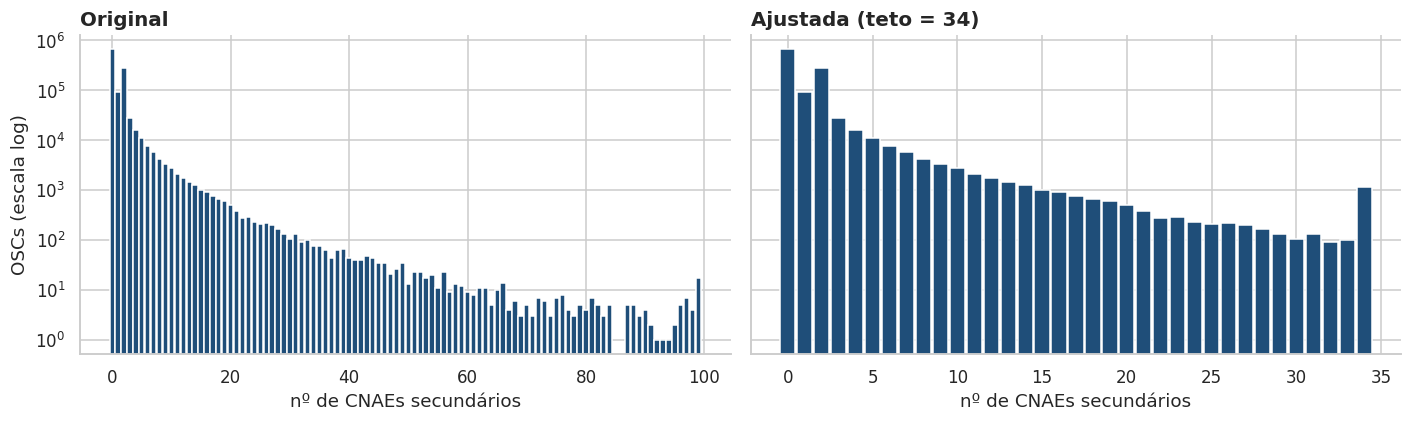

In [6]:
n = t["n_cnae_sec"]
print("Quantis de n_cnae_sec:", {k: int(v) for k, v in n.quantile([.5, .9, .99, .999, .9999]).items()}, "| máximo:", int(n.max()))
q1, q3 = n.quantile([.25, .75]); tukey = q3 + 1.5 * (q3 - q1)
p999 = int(n.quantile(.999))
print(f"Cerca de Tukey (Q3 + 1,5·IQR) = {tukey:.1f}  -> marcaria {br((n > tukey).mean() * 100, 1)}% das OSCs: rígida demais p/ contagem muito assimétrica")
print(f"Critério adotado: teto no percentil 99,9 = {p999} CNAEs secundários -> {br((n > p999).sum())} OSCs acima")

t["flag_outlier_n_cnae_sec"] = (n > p999).astype("int8")
t["n_cnae_sec_aj"] = n.clip(upper=p999).astype("int16")
log("outliers", f"n_cnae_sec acima do percentil 99,9 ({p999})", "n_cnae_sec", t["flag_outlier_n_cnae_sec"].sum(),
    "n_cnae_sec_aj = teto; valor original mantido em n_cnae_sec + flag")

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, serie, tit in [(axes[0], t["n_cnae_sec"], "Original"), (axes[1], t["n_cnae_sec_aj"], f"Ajustada (teto = {p999})")]:
    vc = serie.value_counts().sort_index()
    ax.bar(vc.index, vc.values, color=COR, width=0.9); ax.set_yscale("log"); ax.set_title(tit); ax.set_xlabel("nº de CNAEs secundários")
axes[0].set_ylabel("OSCs (escala log)")
plt.tight_layout(); plt.show()


**Leitura.** A contagem de CNAEs secundários é muito assimétrica (mediana 0, p99 12, máximo 99). A cerca de Tukey (5) marcaria 3,4% das OSCs, o que é rígido demais. Adotei um **teto no percentil 99,9 (34)**: 1.049 OSCs ficam com `n_cnae_sec_aj = 34`, e o valor original é mantido em `n_cnae_sec`, com flag.

Q1 = 1997 | Q3 = 2016 | cerca inferior de Tukey = 1968.5
OSCs fundadas antes de 1968: 5.429 (0,49%)
Ano mais antigo: 1903 | fundadas antes de 1940: 86 | datas futuras (> 2026-08-06): 0
Decisão: manter. São organizações antigas reais; apenas sinalizadas para quem quiser excluí-las de modelos.


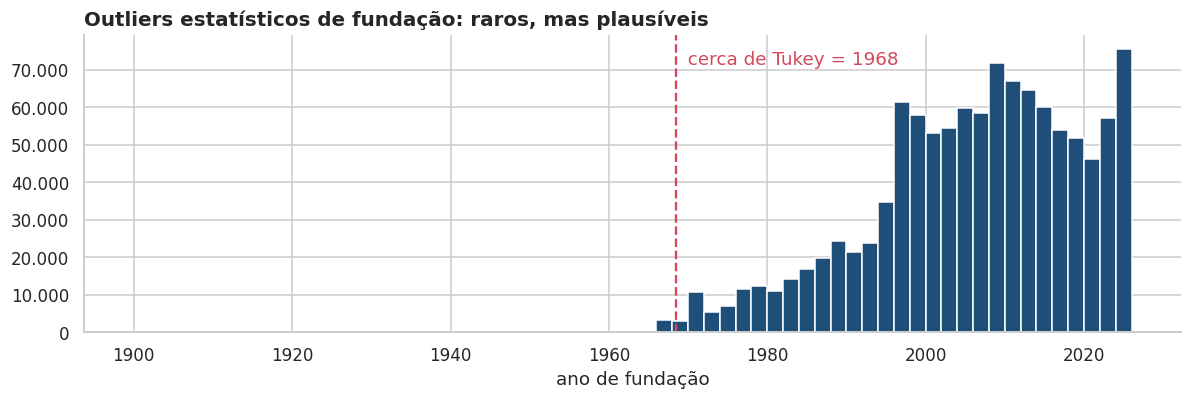

In [7]:
a = t["ano_fundacao"].dropna().astype(int)
q1, q3 = a.quantile([.25, .75]); lim = q1 - 1.5 * (q3 - q1)
t["flag_outlier_ano_fundacao"] = (t["ano_fundacao"] < lim).fillna(False).astype("int8")
log("outliers", f"ano de fundação abaixo da cerca de Tukey ({lim:.0f})", "ano_fundacao", t["flag_outlier_ano_fundacao"].sum(), "mantido + flag (valores plausíveis)")

print(f"Q1 = {q1:.0f} | Q3 = {q3:.0f} | cerca inferior de Tukey = {lim:.1f}")
print(f"OSCs fundadas antes de {lim:.0f}: {br(t['flag_outlier_ano_fundacao'].sum())} ({br(t['flag_outlier_ano_fundacao'].mean() * 100, 2)}%)")
print(f"Ano mais antigo: {a.min()} | fundadas antes de 1940: {br((a < 1940).sum())} | datas futuras (> {DATA_REF.date()}): {int((t['dt_fundacao'] > DATA_REF).sum())}")

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.hist(a, bins=range(1900, 2028, 2), color=COR)
ax.axvline(lim, color=VERM, ls="--"); ax.text(lim, ax.get_ylim()[1] * 0.9, f"  cerca de Tukey = {lim:.0f}", color=VERM)
ax.yaxis.set_major_formatter(fmt_eixo); ax.set_xlabel("ano de fundação"); ax.set_title("Outliers estatísticos de fundação: raros, mas plausíveis")
plt.tight_layout(); plt.show()
print("Decisão: manter. São organizações antigas reais; apenas sinalizadas para quem quiser excluí-las de modelos.")


**Leitura.** Pela cerca de Tukey, 5.429 OSCs (0,49%) foram fundadas antes de 1968. Mas a mais antiga é de 1903 e não há nenhuma data futura. São organizações antigas plausíveis, então **mantive os valores** e só sinalizei (`flag_outlier_ano_fundacao`), para quem quiser excluí-los de modelos.

Suspeitos (d > 2.0º): 2.117 (0,19%) em 663 municípios
Coordenadas erradas repetidas (mesmo ponto em várias OSCs): 216 pontos; o maior concentra 71 OSCs
Distância máxima ao município (graus): 33,8
OSCs exatamente sobre o ponto mediano do município (d = 0): 206.650 (18,6%): indício de geocodificação pelo centro do município

Após a correção, pontos acima de 2.0º: 0
Sem coordenadas: 184


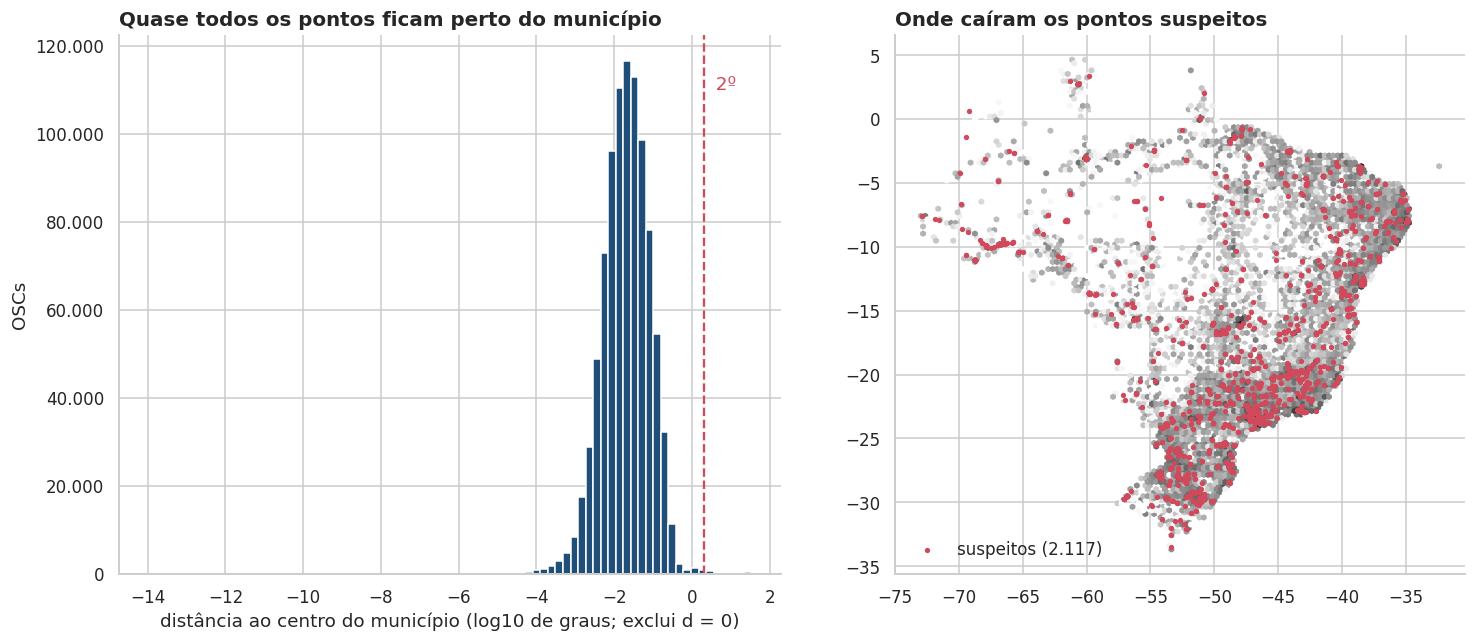

In [8]:
# distância (em graus) entre cada ponto e a mediana de coordenadas do seu município
med = t.groupby("cd_municipio")[["latitude", "longitude"]].transform("median")
d = np.hypot(t["latitude"] - med["latitude"], t["longitude"] - med["longitude"])
LIM = 2.0                                                           # graus (~220 km): maior que quase qualquer município brasileiro
lim = LIM
dd = d.dropna()
susp = (d > lim) & t["latitude"].notna() & t["cd_municipio"].notna()

print(f"Suspeitos (d > {LIM}º): {br(susp.sum())} ({br(susp.mean() * 100, 2)}%) em {br(t.loc[susp, 'cd_municipio'].nunique())} municípios")
rep = t.loc[susp].groupby(["latitude", "longitude"]).size().sort_values(ascending=False)
print(f"Coordenadas erradas repetidas (mesmo ponto em várias OSCs): {br((rep > 1).sum())} pontos; o maior concentra {rep.iloc[0]} OSCs")
print("Distância máxima ao município (graus):", br(d[susp].max(), 1))
zero = int((dd == 0).sum())
print(f"OSCs exatamente sobre o ponto mediano do município (d = 0): {br(zero)} ({br(zero / len(dd) * 100, 1)}%): indício de geocodificação pelo centro do município")

# auditoria: guarda o valor original antes de corrigir
aud = pd.DataFrame({"cnpj": t.loc[susp, "cnpj"],
                    "latitude_original": t.loc[susp, "latitude"].round(6), "longitude_original": t.loc[susp, "longitude"].round(6),
                    "latitude_nova": med.loc[susp, "latitude"].round(6),    "longitude_nova": med.loc[susp, "longitude"].round(6),
                    "distancia_graus": d[susp].round(3)}).reset_index(drop=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
ax = axes[0]
ax.hist(np.log10(dd[dd > 0]), bins=80, color=COR)
ax.axvline(np.log10(2), color=VERM, ls="--"); ax.text(np.log10(2), ax.get_ylim()[1] * .9, "  2º", color=VERM)
ax.set_xlabel("distância ao centro do município (log10 de graus; exclui d = 0)"); ax.set_ylabel("OSCs"); ax.yaxis.set_major_formatter(fmt_eixo)
ax.set_title("Quase todos os pontos ficam perto do município")
ax = axes[1]
ax.hexbin(t["longitude"], t["latitude"], gridsize=120, bins="log", cmap="Greys", mincnt=1)
ax.scatter(aud["longitude_original"], aud["latitude_original"], s=6, color=VERM, label=f"suspeitos ({br(len(aud))})")
ax.set_aspect("equal"); ax.legend(frameon=False, loc="lower left"); ax.set_title("Onde caíram os pontos suspeitos")
plt.tight_layout(); plt.show()

# correção: leva o ponto para a mediana do próprio município
t.loc[susp, ["latitude", "longitude"]] = med.loc[susp, ["latitude", "longitude"]].values
t["latitude"]  = t["latitude"].round(6)
t["longitude"] = t["longitude"].round(6)
t["flag_coord_ajustada"] = susp.astype("int8")
t["flag_coord_ausente"]  = t["latitude"].isna().astype("int8")
log("outliers", "coordenada a mais de 2º (~220 km) da mediana do município", "latitude, longitude", susp.sum(),
    "substituída pela mediana do município + flag_coord_ajustada (originais em aud_coordenada_ajustada)")
log("ausentes", "OSC sem coordenadas (sem município válido para imputar)", "latitude, longitude", t["flag_coord_ausente"].sum(), "mantido NULL + flag_coord_ausente")

d2 = np.hypot(t["latitude"] - t.groupby("cd_municipio")["latitude"].transform("median"), t["longitude"] - t.groupby("cd_municipio")["longitude"].transform("median"))
print(f"\nApós a correção, pontos acima de {LIM}º: {br((d2 > LIM).sum())}")
print(f"Sem coordenadas: {br(t['flag_coord_ausente'].sum())}")


**Leitura.** Aqui há erro de fato: **2.117 OSCs (0,19%) em 663 municípios** estão a mais de 2° (cerca de 220 km) da mediana do próprio município, a até 33,8° de distância. Por exemplo, OSCs de Porto Velho (RO) com coordenadas em São Paulo. Há 216 pontos errados repetidos, e um deles concentra 71 OSCs, típico de geocodificação com falha.

Cada ponto suspeito foi levado à mediana do seu município, com `flag_coord_ajustada`, e os valores originais ficaram em `aud_coordenada_ajustada`. Após a correção, nenhum ponto ultrapassa 2°.

Outro achado: **206.650 OSCs (18,6%) estão exatamente sobre o ponto mediano do município**, indício de geocodificação pelo centro do município. Para análises de proximidade fina, essas coordenadas têm baixa precisão. Foram mantidas, sem flag próprio.

*Limitação:* o critério de 2° é conservador, mas em poucos municípios amazônicos gigantes um ponto legítimo pode ser corrigido; a tabela de auditoria permite reverter.

---
## Etapa 4 · Validação

In [9]:
# ---- antes x depois dos ausentes ---------------------------------------------------------------
MAPA = {"tx_nome_fantasia_osc": "nome_fantasia", "tx_endereco_completo": "endereco_completo", "UF_Sigla": "uf",
        "municipio_nome": "municipio_nome", "cd_municipio": "cd_municipio", "cnae": "cnae", "latitude": "latitude",
        "longitude": "longitude", "natureza_juridica": "natureza_juridica_cod", "dt_fundacao_osc": "dt_fundacao",
        "data_fechamento": "dt_fechamento", "ano_fechamento": "ano_fechamento"}
linhas = []
for orig, antes in ANTES.items():
    if orig in MAPA:                           depois = int(t[MAPA[orig]].isna().sum())
    elif orig.startswith("flags"):             depois = 0
    elif orig == "cnae_secundaria":            depois = "tabela 1:N"
    else:                                      continue
    linhas.append((orig, int(antes), depois))
comp = pd.DataFrame(linhas, columns=["coluna original", "ausentes antes", "ausentes depois"]).set_index("coluna original")
print(comp.to_string(formatters={"ausentes antes": br, "ausentes depois": lambda v: br(v) if not isinstance(v, str) else v}))

# ---- verificações de integridade --------------------------------------------------------------
lat_ok = t["latitude"].dropna().between(-33.76, 5.28).all()
lon_ok = t["longitude"].dropna().between(-74.0, -28.8).all()
flags_bin = all(set(t[c].unique()) <= {0, 1} for c in [f[1] for f in FLAGS] + [c for c in t.columns if c.startswith("flag_")] + ["sem_classificacao_area", "removida_do_mosc"])
uf_cod_ok = (t["cd_municipio"].dropna().str[:2].map(IBGE_UF) == t.loc[t["cd_municipio"].notna(), "uf"]).all()
checks = {
    "CNPJ único (chave primária)": t["cnpj"].is_unique,
    "CNPJ com 14 dígitos e dígito verificador válido": bool(cnpj_valido.all()),
    "UF pertence às 27 UFs": bool(t["uf"].dropna().isin(NOME_UF).all()),
    "UF coerente com o código IBGE do município": bool(uf_cod_ok),
    "todas as flags e indicadores são 0/1": bool(flags_bin),
    "nenhuma data de fundação no futuro": bool((t["dt_fundacao"].dropna() <= DATA_REF).all()),
    "coordenadas dentro do retângulo do Brasil": bool(lat_ok and lon_ok),
    "nenhum texto vazio ('') ou com espaços nas pontas": bool(all(((t[c].dropna() == t[c].dropna().str.strip()) & (t[c].dropna() != "")).all() for c in ["razao_social", "nome_fantasia", "endereco_completo", "municipio_nome"])),
    "CNAE principal sempre com 5 dígitos ou NULL": bool(t["cnae"].dropna().str.fullmatch(r"\d{5}").all()),
    "n_cnae_sec_aj <= n_cnae_sec": bool((t["n_cnae_sec_aj"] <= t["n_cnae_sec"]).all()),
    "nº de linhas preservado": len(t) == 1113949,
}
print()
for k, v in checks.items():
    print(("OK    " if v else "FALHA ") + k)
assert all(checks.values())


                                             ausentes antes ausentes depois
coluna original                                                            
ano_fechamento                                    1.054.202       1.054.202
data_fechamento                                   1.054.202       1.054.202
cnae_secundaria                                     657.397      tabela 1:N
tx_nome_fantasia_osc                                488.830         488.858
flags de área/subárea (26 colunas, em bloco)         26.134               0
cnae                                                 12.927          12.981
tx_endereco_completo                                 12.308          12.308
municipio_nome                                        1.012             184
UF_Sigla                                              1.012             184
natureza_juridica                                       693             693
dt_fundacao_osc                                         693             693
longitude   

**Leitura.** O comparativo explica cada variação:

- **Ausentes que caíram:** UF (1.012 → 184) e flags de área (26.134 → 0).
- **Ausentes que subiram, por regra:** `nome_fantasia` (+28, em branco virou `NULL`), `cnae` (+54, inválidos) e `cd_municipio` (+32, código "0").
- **Sem alteração:** fechamento e data de fundação, que são ausências legítimas.

As 11 verificações de integridade passaram, e o número de linhas foi preservado (1.113.949).

---
## Etapa 5 · Nova base e esquema do banco

In [10]:
# ---- tamanhos de VARCHAR medidos na própria base (com folga) ------------------------------------------
def tam(col, margem=1.25, piso=20):
    return int(max(piso, np.ceil(t[col].str.len().max() * margem / 10) * 10))
V_RAZAO, V_FANT, V_END, V_MUN = tam("razao_social"), tam("nome_fantasia"), tam("endereco_completo"), tam("municipio_nome")
print("VARCHAR:", {"razao_social": V_RAZAO, "nome_fantasia": V_FANT, "endereco_completo": V_END, "municipio_nome": V_MUN})

# ---- especificação da tabela principal: (coluna, tipo SQL, aceita NULL, descrição) ---------------------
ESQ = [
 ("cnpj",                 "CHAR(14)",   False, "CNPJ completo, 14 dígitos (chave primária)"),
 ("cnpj_basico",          "CHAR(8)",    False, "Raiz do CNPJ (identifica a entidade; matriz e filiais compartilham)"),
 ("cnpj_ordem",           "CHAR(4)",    False, "Ordem do estabelecimento no CNPJ (0001 = matriz)"),
 ("razao_social",         f"VARCHAR({V_RAZAO})", False, "Razão social padronizada (maiúsculas, sem espaços extras)"),
 ("nome_fantasia",        f"VARCHAR({V_FANT})",  True,  "Nome fantasia; NULL quando não informado"),
 ("natureza_juridica_cod","CHAR(4)",    True,  "Código da natureza jurídica (FK dim_natureza_juridica); NULL = não informada"),
 ("tipo_estabelecimento", "VARCHAR(7)", False, "Matriz ou Filial (derivado da ordem do CNPJ quando não informado)"),
 ("situacao_cadastral",   "VARCHAR(15)",False, "Ativa, Inapta, Suspensa ou Nula ou Baixada"),
 ("removida_do_mosc",     "TINYINT(1)", False, "1 = removida do MOSC"),
 ("dt_fundacao",          "DATE",       True,  "Data de fundação; NULL quando ausente"),
 ("ano_fundacao",         "SMALLINT",   True,  "Ano da data de fundação"),
 ("dt_fechamento",        "DATE",       True,  "Data de fechamento/saída do cadastro (existe só para parte das baixadas)"),
 ("ano_fechamento",       "SMALLINT",   True,  "Ano da data de fechamento"),
 ("endereco_completo",    f"VARCHAR({V_END})",   True,  "Endereço padronizado"),
 ("cd_municipio",         "CHAR(7)",    True,  "Código IBGE do município (FK dim_municipio); NULL quando inválido"),
 ("uf",                   "CHAR(2)",    True,  "Sigla da UF (FK dim_uf); imputada pelo código IBGE quando ausente"),
 ("latitude",             "DECIMAL(9,6)", True, "Latitude em graus decimais (6 casas, ~0,1 m)"),
 ("longitude",            "DECIMAL(9,6)", True, "Longitude em graus decimais (6 casas, ~0,1 m)"),
 ("cnae",                 "CHAR(5)",    True,  "CNAE principal (5 dígitos); NULL quando ausente ou inválido"),
 ("n_cnae_sec",           "SMALLINT",   False, "Nº de CNAEs secundários distintos (valor original)"),
 ("n_cnae_sec_aj",        "SMALLINT",   False, "Nº de CNAEs secundários com teto no percentil 99,9"),
 ("sem_classificacao_area","TINYINT(1)",False, "1 = OSC sem classificação de área/subárea na origem (flags preenchidas com 0)"),
] + [(f[1], "TINYINT(1)", False, f[2] + " (1/0)") for f in FLAGS] + [
 ("flag_uf_imputada",              "TINYINT(1)", False, "1 = UF recuperada pelo código IBGE"),
 ("flag_tipo_estab_derivado",      "TINYINT(1)", False, "1 = matriz/filial derivado do CNPJ"),
 ("flag_tipo_estab_incoerente",    "TINYINT(1)", False, "1 = matriz/filial informado contradiz a ordem do CNPJ"),
 ("flag_fechamento_antes_fundacao","TINYINT(1)", False, "1 = data de fechamento anterior à fundação"),
 ("flag_cnae_invalido",            "TINYINT(1)", False, "1 = CNAE original fora do padrão (virou NULL)"),
 ("flag_coord_ajustada",           "TINYINT(1)", False, "1 = coordenada suspeita substituída pela mediana do município"),
 ("flag_coord_ausente",            "TINYINT(1)", False, "1 = OSC sem coordenadas"),
 ("flag_possivel_duplicidade",     "TINYINT(1)", False, "1 = possível duplicidade cadastral (ver dup_grupo_id)"),
 ("dup_grupo_id",                  "INT",        True,  "Identificador do grupo de possíveis duplicatas"),
 ("flag_outlier_n_cnae_sec",       "TINYINT(1)", False, "1 = nº de CNAEs secundários acima do percentil 99,9"),
 ("flag_outlier_ano_fundacao",     "TINYINT(1)", False, "1 = ano de fundação abaixo da cerca de Tukey"),
]
COLS_OSC = [e[0] for e in ESQ]
EXTRAS_CSV = ["natureza_juridica", "municipio_nome", "regiao"]        # rótulos úteis na análise (não vão para a tabela osc)
assert set(COLS_OSC) | set(EXTRAS_CSV) == set(t.columns), set(t.columns) ^ (set(COLS_OSC) | set(EXTRAS_CSV))

# ---- tabelas auxiliares ----------------------------------------------------------------------------
dim_uf  = pd.DataFrame({"sigla": list(NOME_UF), "cod_ibge": [COD_UF[s] for s in NOME_UF], "nome": list(NOME_UF.values()), "regiao": [REGIAO[s] for s in NOME_UF]})
dim_nat = pd.DataFrame({"cod": list(NAT_JUR), "descricao": list(NAT_JUR.values())})
dim_mun = t.dropna(subset=["cd_municipio"]).drop_duplicates("cd_municipio")[["cd_municipio", "municipio_nome", "uf"]].rename(columns={"municipio_nome": "nome"}).sort_values("cd_municipio").reset_index(drop=True)
assert dim_mun["cd_municipio"].is_unique and dim_mun["uf"].notna().all()
print(f"dim_uf: {len(dim_uf)} | dim_natureza_juridica: {len(dim_nat)} | dim_municipio: {br(len(dim_mun))} (nomes ausentes: {dim_mun['nome'].isna().sum()}) "
      f"| osc_cnae_secundario: {br(len(sec_df))} | aud_coordenada_ajustada: {br(len(aud))} | log_tratamento: {len(LOG)} regras")

# ---- gerador de DDL (MySQL e SQLite, este usado só para testar a integridade sem servidor) -----------
def gerar_ddl(dialeto="mysql"):
    my = dialeto == "mysql"
    com = lambda s: f" COMMENT '{s.replace(chr(39), chr(39) * 2)}'" if my else ""
    fim = " ENGINE=InnoDB DEFAULT CHARSET=utf8mb4" if my else ""
    def key(nome, cols): return f",\n  KEY {nome} ({cols})" if my else ""
    out = []
    out.append(f"CREATE TABLE IF NOT EXISTS dim_uf (\n  sigla CHAR(2) NOT NULL,\n  cod_ibge CHAR(2) NOT NULL,\n  nome VARCHAR(30) NOT NULL,\n  regiao VARCHAR(15) NOT NULL,\n  PRIMARY KEY (sigla)\n){fim};")
    out.append(f"CREATE TABLE IF NOT EXISTS dim_natureza_juridica (\n  cod CHAR(4) NOT NULL,\n  descricao VARCHAR(60) NOT NULL,\n  PRIMARY KEY (cod)\n){fim};")
    out.append(f"CREATE TABLE IF NOT EXISTS dim_municipio (\n  cd_municipio CHAR(7) NOT NULL,\n  nome VARCHAR({V_MUN}) NULL,\n  uf CHAR(2) NOT NULL,\n  PRIMARY KEY (cd_municipio),\n  CONSTRAINT fk_mun_uf FOREIGN KEY (uf) REFERENCES dim_uf (sigla){key('idx_mun_uf', 'uf')}\n){fim};")
    cols = ",\n".join(f"  {c} {tp} {'NULL' if nul else 'NOT NULL'}{com(d)}" for c, tp, nul, d in ESQ)
    idx = key("idx_osc_basico", "cnpj_basico") + key("idx_osc_uf", "uf") + key("idx_osc_municipio", "cd_municipio") + key("idx_osc_situacao", "situacao_cadastral") \
        + key("idx_osc_natureza", "natureza_juridica_cod") + key("idx_osc_cnae", "cnae") + key("idx_osc_ano_fund", "ano_fundacao")
    out.append(f"CREATE TABLE IF NOT EXISTS osc (\n{cols},\n  PRIMARY KEY (cnpj),\n"
               f"  CONSTRAINT fk_osc_natureza FOREIGN KEY (natureza_juridica_cod) REFERENCES dim_natureza_juridica (cod),\n"
               f"  CONSTRAINT fk_osc_municipio FOREIGN KEY (cd_municipio) REFERENCES dim_municipio (cd_municipio),\n"
               f"  CONSTRAINT fk_osc_uf FOREIGN KEY (uf) REFERENCES dim_uf (sigla){idx}\n){fim};")
    out.append(f"CREATE TABLE IF NOT EXISTS osc_cnae_secundario (\n  cnpj CHAR(14) NOT NULL,\n  cnae CHAR(7) NOT NULL,\n  PRIMARY KEY (cnpj, cnae),\n  CONSTRAINT fk_sec_osc FOREIGN KEY (cnpj) REFERENCES osc (cnpj) ON DELETE CASCADE{key('idx_sec_cnae', 'cnae')}\n){fim};")
    out.append(f"CREATE TABLE IF NOT EXISTS aud_coordenada_ajustada (\n  cnpj CHAR(14) NOT NULL,\n  latitude_original DECIMAL(9,6) NOT NULL,\n  longitude_original DECIMAL(9,6) NOT NULL,\n  latitude_nova DECIMAL(9,6) NOT NULL,\n  longitude_nova DECIMAL(9,6) NOT NULL,\n  distancia_graus DECIMAL(7,3) NOT NULL,\n  PRIMARY KEY (cnpj),\n  CONSTRAINT fk_aud_osc FOREIGN KEY (cnpj) REFERENCES osc (cnpj) ON DELETE CASCADE\n){fim};")
    if my:
        idcol, idpk = "id INT NOT NULL AUTO_INCREMENT,\n", ",\n  PRIMARY KEY (id)"
    else:
        idcol, idpk = "id INTEGER PRIMARY KEY AUTOINCREMENT,\n", ""
    out.append(f"CREATE TABLE IF NOT EXISTS log_tratamento (\n  {idcol}  etapa VARCHAR(30) NOT NULL,\n  regra VARCHAR(250) NOT NULL,\n  coluna VARCHAR(80) NOT NULL,\n  registros_afetados INT NOT NULL,\n  acao VARCHAR(250) NOT NULL{idpk}\n){fim};")
    return "\n\n".join(out) + "\n"

ddl_mysql = gerar_ddl("mysql")
open(f"{SAIDA}/schema.sql", "w", encoding="utf-8").write(ddl_mysql)
print(f"\nschema.sql gerado ({len(ddl_mysql.splitlines())} linhas). Trecho:\n")
print(ddl_mysql[:1100])


VARCHAR: {'razao_social': 220, 'nome_fantasia': 140, 'endereco_completo': 290, 'municipio_nome': 40}
dim_uf: 27 | dim_natureza_juridica: 4 | dim_municipio: 5.570 (nomes ausentes: 0) | osc_cnae_secundario: 1.290.869 | aud_coordenada_ajustada: 2.117 | log_tratamento: 19 regras

schema.sql gerado (124 linhas). Trecho:

CREATE TABLE IF NOT EXISTS dim_uf (
  sigla CHAR(2) NOT NULL,
  cod_ibge CHAR(2) NOT NULL,
  nome VARCHAR(30) NOT NULL,
  regiao VARCHAR(15) NOT NULL,
  PRIMARY KEY (sigla)
) ENGINE=InnoDB DEFAULT CHARSET=utf8mb4;

CREATE TABLE IF NOT EXISTS dim_natureza_juridica (
  cod CHAR(4) NOT NULL,
  descricao VARCHAR(60) NOT NULL,
  PRIMARY KEY (cod)
) ENGINE=InnoDB DEFAULT CHARSET=utf8mb4;

CREATE TABLE IF NOT EXISTS dim_municipio (
  cd_municipio CHAR(7) NOT NULL,
  nome VARCHAR(40) NULL,
  uf CHAR(2) NOT NULL,
  PRIMARY KEY (cd_municipio),
  CONSTRAINT fk_mun_uf FOREIGN KEY (uf) REFERENCES dim_uf (sigla),
  KEY idx_mun_uf (uf)
) ENGINE=InnoDB DEFAULT CHARSET=utf8mb4;

CREATE TABL

**Leitura.** O esquema separa o que é dimensão do que é fato:

- `osc` (1 linha por CNPJ, 59 colunas), com as flags de área e de qualidade.
- `dim_uf` (27), `dim_municipio` (5.570) e `dim_natureza_juridica` (4).
- `osc_cnae_secundario` (1,29 mi, relação 1:N).
- `aud_coordenada_ajustada` (2.117) e `log_tratamento` (19 regras).

Um detalhe técnico: a coluna original `SubArea_Associacoes_de_atividades_nao_especificadas_anteriormente` tem 65 caracteres e estouraria o limite de 64 do MySQL. Por isso as 26 flags ganharam nomes curtos (`area_*` e `sub_*`). O `dicionario_dados.csv` documenta todas as colunas, e o `schema.sql` as traz como `COMMENT`.

In [11]:
base = t[COLS_OSC + EXTRAS_CSV]
base.to_csv(f"{SAIDA}/MOSC_tratada.csv", index=False, na_rep="", encoding="utf-8", lineterminator="\n", date_format="%Y-%m-%d", float_format="%.6f")
dim_uf.to_csv(f"{SAIDA}/dim_uf.csv", index=False, encoding="utf-8", lineterminator="\n")
dim_nat.to_csv(f"{SAIDA}/dim_natureza_juridica.csv", index=False, encoding="utf-8", lineterminator="\n")
dim_mun.to_csv(f"{SAIDA}/dim_municipio.csv", index=False, na_rep="", encoding="utf-8", lineterminator="\n")
sec_df.to_csv(f"{SAIDA}/osc_cnae_secundario.csv", index=False, encoding="utf-8", lineterminator="\n")
aud.to_csv(f"{SAIDA}/aud_coordenada_ajustada.csv", index=False, float_format="%.6f", encoding="utf-8", lineterminator="\n")
pd.DataFrame(LOG).to_csv(f"{SAIDA}/log_tratamento.csv", index=False, encoding="utf-8", lineterminator="\n")
pd.DataFrame(ESQ, columns=["coluna", "tipo_sql", "aceita_nulo", "descricao"]).to_csv(f"{SAIDA}/dicionario_dados.csv", index=False, encoding="utf-8", lineterminator="\n")

print(f"{'arquivo':<34}{'linhas':>12}{'tamanho':>12}")
for f in sorted(os.listdir(SAIDA)):
    p = os.path.join(SAIDA, f)
    n = sum(1 for _ in open(p, encoding="utf-8")) - 1 if f.endswith(".csv") else sum(1 for _ in open(p, encoding="utf-8"))
    print(f"{f:<34}{br(n):>12}{br(os.path.getsize(p) / 1e6, 1):>9} MB")
print("\nColunas da base tratada:", base.shape[1], "| pré-visualização:")
print(base.iloc[:3, :12].to_string())


arquivo                                 linhas     tamanho
MOSC_tratada.csv                     1.113.949    397,3 MB
aud_coordenada_ajustada.csv              2.117      0,1 MB
dicionario_dados.csv                        59      0,0 MB
dim_municipio.csv                        5.570      0,1 MB
dim_natureza_juridica.csv                    4      0,0 MB
dim_uf.csv                                  27      0,0 MB
log_tratamento.csv                          19      0,0 MB
osc_cnae_secundario.csv              1.290.869     29,7 MB
schema.sql                                 124      0,0 MB

Colunas da base tratada: 62 | pré-visualização:
             cnpj cnpj_basico cnpj_ordem                                                   razao_social           nome_fantasia natureza_juridica_cod tipo_estabelecimento situacao_cadastral  removida_do_mosc dt_fundacao  ano_fundacao dt_fechamento
0  01022772000197    01022772       0001                   ASSOC DE PAIS PROF DA ESC BENJAMIM CONSTANTE  APP BENJ

**Leitura.** A base tratada (`MOSC_tratada.csv`) mantém as **1.113.949 linhas** e passa a ter 62 colunas: as 59 da tabela `osc` mais três rótulos legíveis (`natureza_juridica`, `municipio_nome`, `regiao`) que o importador descarta ao carregar. Coordenadas usam ponto decimal e 6 casas, datas seguem o padrão ISO, e o texto é UTF-8.

---
## Etapa 6 · Importação para o MySQL

**Importante:** não há servidor MySQL neste ambiente, então a carga real **não foi executada aqui**. Para reduzir o risco, a célula abaixo ensaia o mesmo processo com o SQLite, que está na biblioteca padrão do Python: cria as mesmas tabelas, carrega os mesmos CSVs com a mesma lógica do importador (descartar colunas extras e converter `''` em `NULL`), liga as chaves estrangeiras e confere os totais contra o pandas.

In [12]:
import sqlite3, time
DB = os.path.join(SAIDA, "_teste_integridade.sqlite")
if os.path.exists(DB): os.remove(DB)
con = sqlite3.connect(DB); cur = con.cursor()
cur.execute("PRAGMA foreign_keys = ON")
for stmt in gerar_ddl("sqlite").split(";\n"):
    if stmt.strip(): cur.execute(stmt)

def carregar_csv(tabela, arquivo, chunk=100_000):
    """Replica o que o LOAD DATA do MySQL fará: lê o CSV, descarta colunas extras e converte '' em NULL."""
    cols_tab = [r[1] for r in cur.execute(f"PRAGMA table_info({tabela})")]
    n = 0
    for ch in pd.read_csv(os.path.join(SAIDA, arquivo), dtype=str, keep_default_na=False, chunksize=chunk):
        cols = [c for c in ch.columns if c in cols_tab]
        dados = ch[cols].astype(object).where(ch[cols] != "", None)
        cur.executemany(f"INSERT INTO {tabela} ({','.join(cols)}) VALUES ({','.join('?' * len(cols))})",
                        dados.itertuples(index=False, name=None))
        n += len(ch)
    con.commit()
    return n

ORDEM = [("dim_uf", "dim_uf.csv"), ("dim_natureza_juridica", "dim_natureza_juridica.csv"), ("dim_municipio", "dim_municipio.csv"),
         ("osc", "MOSC_tratada.csv"), ("osc_cnae_secundario", "osc_cnae_secundario.csv"),
         ("aud_coordenada_ajustada", "aud_coordenada_ajustada.csv"), ("log_tratamento", "log_tratamento.csv")]
for tabela, arq in ORDEM:
    t0 = time.time(); n = carregar_csv(tabela, arq)
    print(f"{tabela:<26}{br(n):>12} linhas  ({time.time() - t0:.1f}s)")

viol = cur.execute("PRAGMA foreign_key_check").fetchall()
print(f"\nViolações de chave estrangeira: {len(viol)}")

q = lambda sql: cur.execute(sql).fetchall()
print("Contagem por situação bate com o pandas :", dict(q("SELECT situacao_cadastral, COUNT(*) FROM osc GROUP BY 1")) == t["situacao_cadastral"].value_counts().to_dict())
print("Soma da flag área Religião bate         :", q("SELECT SUM(area_religiao) FROM osc")[0][0] == int(t["area_religiao"].sum()))
print("UF nula bate                            :", q("SELECT COUNT(*) FROM osc WHERE uf IS NULL")[0][0] == int(t["uf"].isna().sum()))
print("Coordenadas nulas batem                 :", q("SELECT COUNT(*) FROM osc WHERE latitude IS NULL")[0][0] == int(t["latitude"].isna().sum()))
print("CNAEs secundários x n_cnae_sec          :", q("SELECT COUNT(*) FROM osc_cnae_secundario")[0][0] == int(t["n_cnae_sec"].sum()))

print("\nConsulta de exemplo (OSCs ativas por região, via JOIN):")
for r in q("""SELECT u.regiao, COUNT(*) AS ativas FROM osc o JOIN dim_uf u ON u.sigla = o.uf
              WHERE o.situacao_cadastral = 'Ativa' GROUP BY u.regiao ORDER BY ativas DESC"""):
    print(f"  {r[0]:<14}{br(r[1]):>10}")
con.close(); os.remove(DB)            # banco de teste descartado (o real será o MySQL)


dim_uf                              27 linhas  (0.0s)
dim_natureza_juridica                4 linhas  (0.0s)
dim_municipio                    5.570 linhas  (0.0s)
osc                          1.113.949 linhas  (28.3s)
osc_cnae_secundario          1.290.869 linhas  (4.1s)
aud_coordenada_ajustada          2.117 linhas  (0.0s)
log_tratamento                      19 linhas  (0.0s)

Violações de chave estrangeira: 0
Contagem por situação bate com o pandas : True
Soma da flag área Religião bate         : True
UF nula bate                            : True
Coordenadas nulas batem                 : True
CNAEs secundários x n_cnae_sec          : True

Consulta de exemplo (OSCs ativas por região, via JOIN):
  Sudeste          267.182
  Nordeste         136.725
  Sul              123.054
  Centro-Oeste      55.247
  Norte             42.383


**Leitura.** Os 1.113.949 registros e 1.290.869 CNAEs secundários carregaram sem nenhuma violação de chave estrangeira, e os totais por situação, flags, UF nula e coordenadas nulas batem com o pandas. Isso valida **a integridade dos dados e a lógica de carga**; a sintaxe específica do MySQL só é conferida na sua primeira execução.

O script abaixo executa o `schema.sql` e carrega cada tabela com `LOAD DATA LOCAL INFILE`, o caminho mais rápido do MySQL. Ele converte texto vazio em `NULL`, ignora as colunas extras do CSV, aceita o `.csv.gz` (descompacta sozinho) e confere a contagem de linhas de cada tabela.

In [13]:
# gera o script de importação (a mesma versão acompanha este notebook)
SCRIPT = r'''#!/usr/bin/env python3
# Importa a base tratada do MOSC para o MySQL 8.x (ou MariaDB 10.x).
#
# Preparação (uma vez):
#   pip install pymysql
#   no servidor:  SET GLOBAL local_infile = 1;      (necessário para o LOAD DATA LOCAL)
#
# Uso:
#   python importar_mysql.py --host localhost --user root --password SUA_SENHA --database mosc --pasta saida_tratamento --recriar
import argparse, csv, gzip, os, shutil, sys, time
import pymysql

ORDEM = [
    ("dim_uf", "dim_uf.csv"),
    ("dim_natureza_juridica", "dim_natureza_juridica.csv"),
    ("dim_municipio", "dim_municipio.csv"),
    ("osc", "MOSC_tratada.csv"),
    ("osc_cnae_secundario", "osc_cnae_secundario.csv"),
    ("aud_coordenada_ajustada", "aud_coordenada_ajustada.csv"),
    ("log_tratamento", "log_tratamento.csv"),
]


def garantir_csv(caminho):
    # o LOAD DATA não lê .gz: se só existir o .csv.gz, descompacta ao lado
    if not os.path.exists(caminho) and os.path.exists(caminho + ".gz"):
        print(f"  descompactando {caminho}.gz ...")
        with gzip.open(caminho + ".gz", "rb") as f_in, open(caminho, "wb") as f_out:
            shutil.copyfileobj(f_in, f_out)
    if not os.path.exists(caminho):
        sys.exit(f"Arquivo não encontrado: {caminho}")
    return caminho


def comandos_do_schema(caminho):
    with open(caminho, encoding="utf-8") as f:
        texto = f.read()
    return [c.strip() for c in texto.split(";\n") if c.strip()]


def carregar(cur, tabela, caminho):
    with open(caminho, encoding="utf-8", newline="") as f:
        leitor = csv.reader(f)
        cabecalho = next(leitor)
        n_csv = sum(1 for _ in leitor)

    cur.execute(f"SHOW COLUMNS FROM `{tabela}`")
    colunas_tabela = {linha[0] for linha in cur.fetchall()}

    variaveis, atribuicoes, descartadas = [], [], []
    for i, col in enumerate(cabecalho):
        variaveis.append(f"@v{i}")
        if col in colunas_tabela:
            atribuicoes.append(f"`{col}` = NULLIF(@v{i}, '')")   # texto vazio vira NULL
        else:
            descartadas.append(col)                               # coluna extra do CSV (rótulos): ignorada

    caminho_sql = os.path.abspath(caminho).replace("\\", "/").replace("'", "''")
    sql = (
        f"LOAD DATA LOCAL INFILE '{caminho_sql}' INTO TABLE `{tabela}` CHARACTER SET utf8mb4 "
        "FIELDS TERMINATED BY ',' OPTIONALLY ENCLOSED BY '\"' ESCAPED BY '' "
        "LINES TERMINATED BY '\\n' IGNORE 1 LINES "
        f"({', '.join(variaveis)}) SET {', '.join(atribuicoes)}"
    )
    t0 = time.time()
    cur.execute(sql)
    cur.execute(f"SELECT COUNT(*) FROM `{tabela}`")
    n_db = cur.fetchone()[0]
    status = "OK" if n_db == n_csv else "DIVERGENTE"
    extra = f" | colunas ignoradas: {', '.join(descartadas)}" if descartadas else ""
    print(f"  {tabela:<26}{n_csv:>10,} linhas no CSV | {n_db:>10,} na tabela | {status} | {time.time() - t0:.1f}s{extra}")
    cur.execute("SHOW WARNINGS")
    avisos = cur.fetchall()
    if avisos:
        print(f"    {len(avisos)} aviso(s); primeiro: {avisos[0]}")
    return n_db == n_csv


def main():
    ap = argparse.ArgumentParser(description="Importa a base tratada do MOSC para o MySQL")
    ap.add_argument("--host", default="localhost")
    ap.add_argument("--port", type=int, default=3306)
    ap.add_argument("--user", default="root")
    ap.add_argument("--password", default="")
    ap.add_argument("--database", default="mosc")
    ap.add_argument("--pasta", default="saida_tratamento", help="pasta com os CSVs e o schema.sql")
    ap.add_argument("--recriar", action="store_true", help="apaga o banco antes de criar (CUIDADO)")
    args = ap.parse_args()

    con = pymysql.connect(host=args.host, port=args.port, user=args.user, password=args.password,
                          charset="utf8mb4", local_infile=True, autocommit=True)
    cur = con.cursor()
    if args.recriar:
        cur.execute(f"DROP DATABASE IF EXISTS `{args.database}`")
    cur.execute(f"CREATE DATABASE IF NOT EXISTS `{args.database}` CHARACTER SET utf8mb4")
    cur.execute(f"USE `{args.database}`")

    print("Criando tabelas (schema.sql) ...")
    for comando in comandos_do_schema(os.path.join(args.pasta, "schema.sql")):
        cur.execute(comando)

    print("Carregando dados ...")
    tudo_ok = True
    for tabela, arquivo in ORDEM:
        caminho = garantir_csv(os.path.join(args.pasta, arquivo))
        try:
            tudo_ok &= carregar(cur, tabela, caminho)
        except pymysql.err.OperationalError as e:
            if e.args and e.args[0] in (1148, 3948):
                sys.exit("O servidor bloqueou LOAD DATA LOCAL. Rode no MySQL:  SET GLOBAL local_infile = 1;  e tente de novo.")
            raise

    print("\nVerificações de integridade:")
    consultas = {
        "OSCs sem UF válida (órfãs)": "SELECT COUNT(*) FROM osc o LEFT JOIN dim_uf u ON u.sigla = o.uf WHERE o.uf IS NOT NULL AND u.sigla IS NULL",
        "OSCs sem município válido (órfãs)": "SELECT COUNT(*) FROM osc o LEFT JOIN dim_municipio m ON m.cd_municipio = o.cd_municipio WHERE o.cd_municipio IS NOT NULL AND m.cd_municipio IS NULL",
        "CNAEs secundários sem OSC (órfãos)": "SELECT COUNT(*) FROM osc_cnae_secundario s LEFT JOIN osc o ON o.cnpj = s.cnpj WHERE o.cnpj IS NULL",
    }
    for nome, sql in consultas.items():
        cur.execute(sql)
        print(f"  {nome:<40}{cur.fetchone()[0]}")
    print("\nConcluído." if tudo_ok else "\nConcluído com divergências: revise as linhas marcadas acima.")
    con.close()


if __name__ == "__main__":
    main()
'''
open('importar_mysql.py', 'w', encoding='utf-8').write(SCRIPT)
print('importar_mysql.py gravado:', len(SCRIPT.splitlines()), 'linhas')


importar_mysql.py gravado: 127 linhas


### Como importar

1. No servidor MySQL, habilite o carregamento local (necessário uma única vez):

```sql
SET GLOBAL local_infile = 1;
```

2. Instale o driver e execute o importador, a partir da pasta que contém `importar_mysql.py` e `saida_tratamento/`:

```bash
pip install pymysql
python importar_mysql.py --host localhost --user root --password SUA_SENHA --database mosc --pasta saida_tratamento --recriar
```

3. Confira no MySQL:

```sql
USE mosc;
SELECT situacao_cadastral, COUNT(*) FROM osc GROUP BY 1;   -- Ativa 624.629 · Inapta 337.024 · Nula ou Baixada 145.930 · Suspensa 6.366
SELECT COUNT(*) FROM osc_cnae_secundario;                  -- 1.290.869
```

`--recriar` **apaga o banco `mosc`** antes de criar. Omita-o se quiser preservar dados existentes. A carga da tabela `osc` (1,1 milhão de linhas, 59 colunas) costuma levar de 1 a 3 minutos com `LOAD DATA`.

---
## Resumo das decisões

| Problema | Diagnóstico | Decisão |
|---|---|---|
| Encoding misto | UTF-8 e Latin-1 na mesma linha | Reconversão para UTF-8 |
| Texto | Espaços extras, caixa mista, 28 "vazios" | Trim, colapso de espaços, maiúsculas, vazio = `NULL` |
| UF ausente | 828 recuperáveis pelo código IBGE | Imputada + `flag_uf_imputada` |
| Município sem nome | 5 municípios novos | Extraído do endereço (96,4% de concordância) |
| Matriz/filial "Não Identificado" | 145.930 baixadas | Derivado da ordem do CNPJ + flag |
| Flags de área ausentes | 26.134 em bloco | 0 + `sem_classificacao_area` |
| CNAE com 4 dígitos | 54 | `NULL` + flag |
| CNPJ duplicado | 0 | Nada a remover |
| Duplicidade cadastral | 258 grupos / 665 linhas | Mantidas + flag + grupo |
| CNAEs secundários | cauda até 99 | Teto no p99,9 (34) + valor original |
| Ano de fundação | 5.429 abaixo da cerca de Tukey | Mantidos + flag |
| Coordenadas | 2.117 fora do município | Mediana municipal + flag + auditoria |

### Pontos que merecem a sua decisão

- **Flags de área com 0 para quem não tem classificação.** Se preferir `NULL`, basta remover o `fillna(0)` na célula de construção; a coluna `sem_classificacao_area` já permite filtrar.
- **Coordenadas no centro do município (18,6%).** Estão mantidas, mas podem ser excluídas de análises espaciais finas.
- **Possíveis duplicidades.** Os 258 grupos precisam de revisão humana ou de uma regra de negócio.
- **MySQL real.** A primeira execução no seu servidor é o teste final da sintaxe do `schema.sql` e do `LOAD DATA`.